In [1]:
!pip install pandas numpy matplotlib scikit-learn

# Forecast Verification Backtesting (Device 08)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score, mean_absolute_error

df = pd.read_csv('/Users/anshul/Documents/AI/data/raw/MOSFET/MOSFET_Device_08.csv')
df = df.dropna(subset=['Aging_Hours', 'RDS_on_Ohm']).sort_values('Aging_Hours')

# Cutoff at 100 hours
cutoff_hour = 100.0
train_df = df[df['Aging_Hours'] <= cutoff_hour]
test_df = df[df['Aging_Hours'] > cutoff_hour]

print(f"Training on {len(train_df)} points (0 to 100h).")
print(f"Testing on {len(test_df)} points (100h to 131.9h).")

X_train = train_df[['Aging_Hours']]
y_train = train_df['RDS_on_Ohm']
X_test = test_df[['Aging_Hours']]
y_test = test_df['RDS_on_Ohm']

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)

print(f"--- REGRESSION ERROR ---")
print(f"Mean Absolute Error (MAE) for future points: {mae:.4f} Ohm")

# Classification Verification (Anomaly Detection)
threshold = y_train.max() * 1.05 # Dynamic threshold for demonstration (5% over max training value)
actual_flags = (y_test > threshold).astype(int)
predicted_flags = (y_pred > threshold).astype(int)

acc = accuracy_score(actual_flags, predicted_flags)
rec = recall_score(actual_flags, predicted_flags, zero_division=0)
prec = precision_score(actual_flags, predicted_flags, zero_division=0)

print(f"\nUsing dynamic anomaly threshold of {threshold:.4f} Ohm")
print("\n--- CLASSIFICATION METRICS (Forecast Verification) ---")
print(f"Accuracy : {acc*100:.2f}%")
print(f"Recall   : {rec*100:.2f}%")
print(f"Precision: {prec*100:.2f}%")


Training on 26565 points (0 to 100h).
Testing on 37611 points (100h to 131.9h).
--- REGRESSION ERROR ---
Mean Absolute Error (MAE) for future points: 4.6966 Ohm

Using dynamic anomaly threshold of 2.4843 Ohm

--- CLASSIFICATION METRICS (Forecast Verification) ---
Accuracy : 11.11%
Recall   : 100.00%
Precision: 11.11%


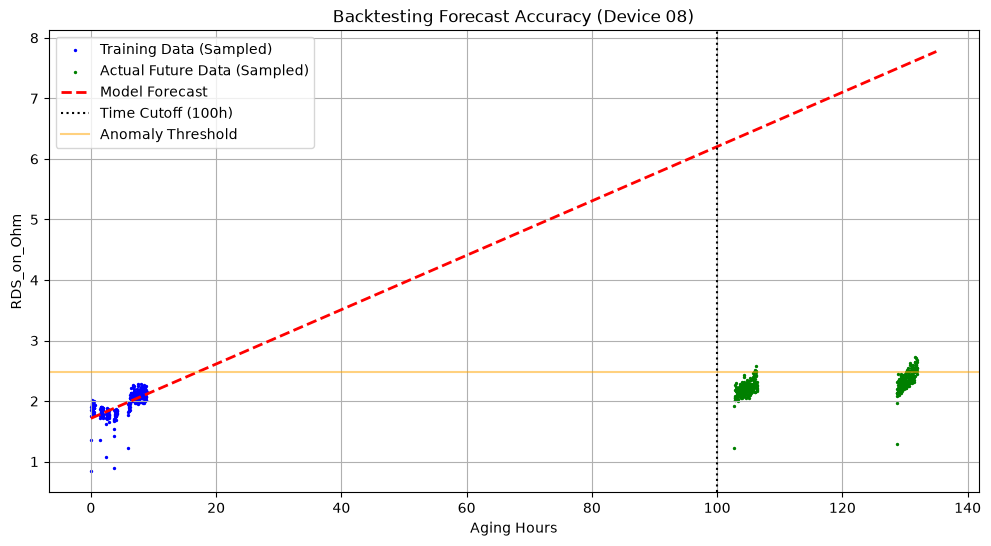

In [3]:
plt.figure(figsize=(12, 6))
# Plot 1% of points to not crash browser with massive scatter
plt.scatter(X_train[::100], y_train[::100], color='blue', s=2, label='Training Data (Sampled)')
plt.scatter(X_test[::100], y_test[::100], color='green', s=2, label='Actual Future Data (Sampled)')

X_plot = pd.DataFrame({'Aging_Hours': np.linspace(0, 135, 500)})
plt.plot(X_plot, model.predict(X_plot), color='red', linestyle='--', linewidth=2, label='Model Forecast')

plt.axvline(x=cutoff_hour, color='black', linestyle=':', label='Time Cutoff (100h)')
plt.axhline(y=threshold, color='orange', linestyle='-', alpha=0.5, label='Anomaly Threshold')
plt.title('Backtesting Forecast Accuracy (Device 08)')
plt.xlabel('Aging Hours')
plt.ylabel('RDS_on_Ohm')
plt.legend()
plt.grid(True)
plt.show()
